In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [236]:
# Plot customization
sns.set_style("whitegrid")
sns.despine(left=True)
colors = sns.color_palette('hls')
binary_colors = sns.color_palette('tab10')[:2]
binary_colors_2 = sns.color_palette(palette='icefire')[:2]
save_dir = '../Data/Raw data/visualizations'

<Figure size 640x480 with 0 Axes>

In [169]:
subscriptions = pd.read_csv('../Data/Raw data/subscriptions.csv')
usage = pd.read_csv('../Data/Raw data/usage.csv')

In [4]:
subscriptions.sample(10)

,customer_id,signup_date,plan_type,plan_tier,monthly_price,acquisition_channel,primary_device,age_group,churned,churn_date,cancel_reason
3024,3025,2025-09-07,monthly,premium,29.99,referral,ios,35-44,yes,2025-10-06,not_using_enough
405,406,2024-08-12,monthly,basic,12.99,referral,android,35-44,yes,2025-07-07,technical_issues
1291,1292,2025-07-09,monthly,premium,29.99,organic,ios,18-24,no,NaN,NaN
3886,3887,2025-03-01,monthly,basic,12.99,organic,android,25-34,yes,2025-07-19,not_using_enough
2041,2042,2025-07-01,monthly,plus,19.99,organic,android,18-24,yes,2025-12-15,not_using_enough
2178,2179,2025-07-27,annual,basic,9.74,paid_social,web,35-44,no,NaN,NaN
695,696,2025-06-23,monthly,plus,19.99,promo_offer,android,18-24,no,NaN,NaN
1538,1539,2025-06-26,monthly,plus,19.99,referral,ios,45-54,no,NaN,NaN
1832,1833,2025-01-16,monthly,premium,29.99,promo_offer,ios,25-34,yes,2025-05-11,other
3043,3044,2025-04-12,monthly,Basic,12.99,paid_social,android,25-34,yes,2025-12-30,not_using_enough


In [5]:
usage.sample(10)

,customer_id,month,workouts_completed,minutes_active,classes_booked,support_tickets
18887,2593,2025-01,1,22.0,0,0
10436,1440,2024-12,0,0.0,0,0
24297,3330,2025-11,1,25.0,0,0
30210,4136,2025-03,2,46.0,0,0
14541,2022,2025-05,2,46.0,1,0
5327,743,2025-10,0,0.0,0,1
3662,513,2025-07,7,202.0,0,1
15572,2154,2025-01,2,61.0,0,0
9052,1248,2025-10,4,96.0,1,0
13409,1863,2024-12,10,183.0,1,0


In [170]:
# Replacing missing minutes_active values with 0 where workouts_completed is 0.
usage.loc[usage['workouts_completed'] == 0, ['minutes_active']] = usage.loc[usage['workouts_completed'] == 0, ['minutes_active']].fillna(0)
usage = usage.dropna()

In [171]:
# Replacing missing values for churned customers without cancelling reason with 'didnt_specify'.
missing_reasons = (subscriptions['churned'] == 'yes') & (subscriptions['cancel_reason'].isna())
subscriptions.loc[missing_reasons, 'cancel_reason'] = subscriptions.loc[missing_reasons, 'cancel_reason'].fillna("not_specified")

In [172]:
subscriptions['plan_tier'] = subscriptions['plan_tier'].str.lower()

In [177]:
subscriptions.sample(10)

,customer_id,signup_date,plan_type,plan_tier,monthly_price,acquisition_channel,primary_device,age_group,churned,churn_date,cancel_reason
4165,4166,2025-09-30,monthly,basic,12.99,paid_social,web,18-24,yes,2025-10-22,too_expensive
1792,1793,2025-01-22,monthly,basic,12.99,referral,ios,55+,no,NaN,NaN
2038,2039,2025-08-22,monthly,plus,19.99,organic,android,25-34,no,NaN,NaN
2857,2858,2025-10-18,monthly,premium,29.99,paid_social,ios,25-34,no,NaN,NaN
1804,1805,2024-09-23,monthly,basic,12.99,promo_offer,android,25-34,yes,2024-11-23,too_expensive
1294,1295,2025-06-28,monthly,basic,12.99,organic,web,18-24,no,NaN,NaN
804,805,2025-01-27,monthly,basic,12.99,paid_social,android,35-44,yes,2025-05-07,too_expensive
375,376,2025-05-27,monthly,basic,12.99,organic,android,25-34,yes,2025-09-03,not_using_enough
4046,4047,2025-07-11,monthly,plus,19.99,promo_offer,ios,25-34,yes,2025-07-22,found_alternative
2828,2829,2025-09-06,monthly,plus,19.99,partner,ios,35-44,no,NaN,NaN


In [177]:
subscriptions.info()

<class 'pandas.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          4200 non-null   int64  
 1   signup_date          4200 non-null   str    
 2   plan_type            4200 non-null   str    
 3   plan_tier            4200 non-null   str    
 4   monthly_price        4200 non-null   float64
 5   acquisition_channel  4200 non-null   str    
 6   primary_device       4200 non-null   str    
 7   age_group            4200 non-null   str    
 8   churned              4200 non-null   str    
 9   churn_date           1768 non-null   str    
 10  cancel_reason        1768 non-null   str    
dtypes: float64(1), int64(1), str(9)
memory usage: 361.1 KB


In [180]:
usage.info()

<class 'pandas.DataFrame'>
Index: 30234 entries, 0 to 30684
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         30234 non-null  int64  
 1   month               30234 non-null  str    
 2   workouts_completed  30234 non-null  int64  
 3   minutes_active      30234 non-null  float64
 4   classes_booked      30234 non-null  int64  
 5   support_tickets     30234 non-null  int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 1.6 MB


In [181]:
# Filtering out columns not needed for visualizations.
filtered_df = subscriptions.drop(['signup_date', 'monthly_price', 'churn_date'], axis=1)

active_customers = filtered_df.loc[subscriptions['churned'] == 'no']
active_customers = active_customers.drop('cancel_reason', axis=1)       #Dropping cancel_reason since they're still customers.
churned_customers = filtered_df.loc[subscriptions['churned'] == 'yes']

age_ascending = order=subscriptions.sort_values('age_group')['age_group']

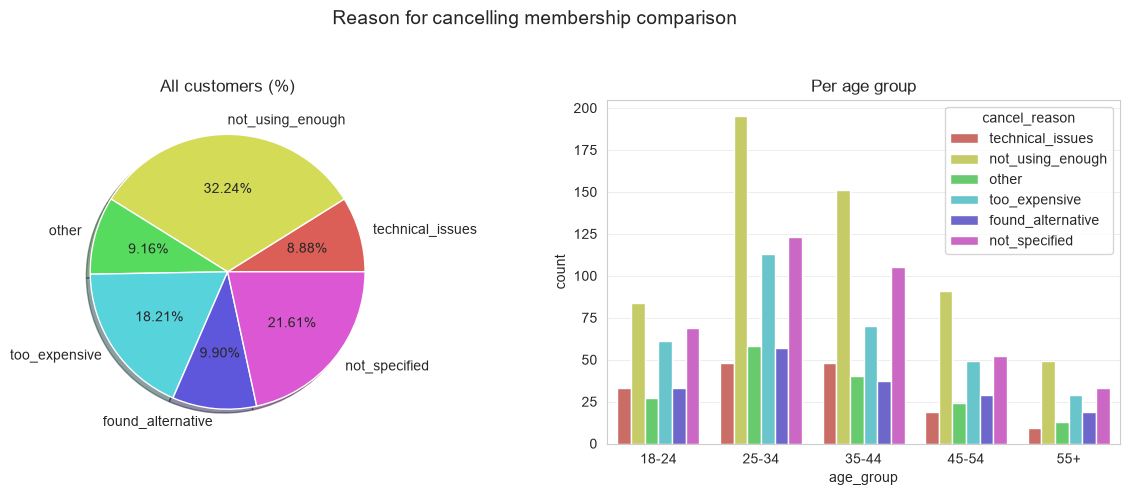

In [229]:
# Plots for cancelling membership count and percentage.
churn_reason_count = churned_customers['cancel_reason'].value_counts(sort=False)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 5))

ax0.pie(churn_reason_count, labels=churn_reason_count.index, colors=colors, autopct='%.2f%%', shadow=True)
ax0.set_title('All customers (%).', loc='center', fontsize=12)

ax1 = sns.countplot(churned_customers, x='age_group', hue='cancel_reason', palette=colors, order=age_ascending)
ax1.set_title('Per age group.', loc='center', fontsize=12)

plt.suptitle('Reason for cancelling membership comparison.', fontsize=14)
plt.tight_layout()
fig.subplots_adjust(top=0.80)   #Adjusts subtitles placement

#plt.savefig(f'{save_dir}/cancelling_membership_comparison.jpg')
plt.show()

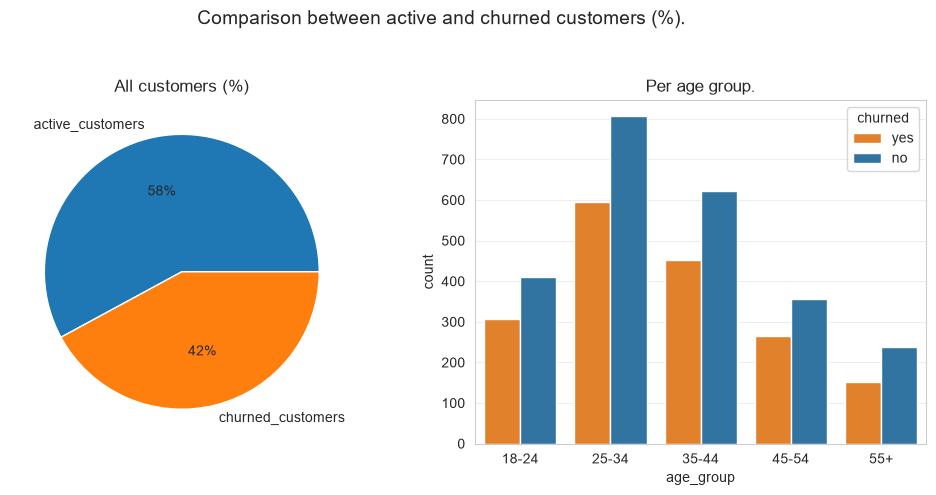

In [227]:
#Pie chart comparison between churned customers and active customers.
churned_percentage = filtered_df['churned'].value_counts()

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 5))

ax0.pie(churned_percentage, labels=('active_customers', 'churned_customers'), colors=binary_colors, autopct='%.0f%%')
ax0.set_title('All customers (%).', loc='center', fontsize=12)

ax1 = sns.countplot(filtered_df, x='age_group', hue='churned', order=age_ascending, palette=(binary_colors[1], binary_colors[0]))
ax1.set_title('Per age group.', loc='center', fontsize=12)

plt.suptitle('Comparison between active and churned customers (%).', fontsize=14)
plt.tight_layout()
plt.subplots_adjust(top=0.80)
#plt.savefig(f'{save_dir}/customer_comparison_all.jpg')
plt.show()

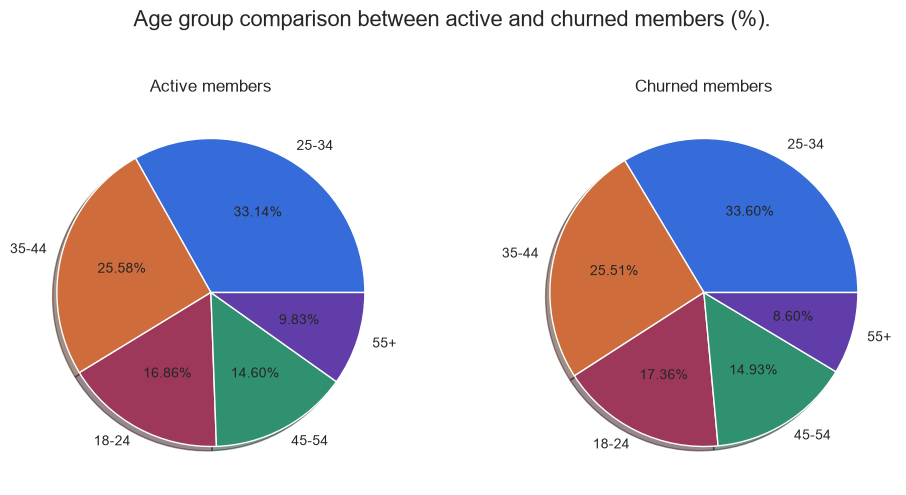

In [232]:
# Age group comparison between active and churned customers.
active_age_group = active_customers['age_group'].value_counts()
churned_age_group = churned_customers['age_group'].value_counts()

fig, (ax0, ax1)= plt.subplots(1, 2, figsize=(10, 5))

ax0.pie(active_age_group, labels=active_age_group.index, autopct='%.2f%%', shadow=True)
ax0.set_title('Active members.', loc='center', fontsize=12)

ax1.pie(churned_age_group, labels=churned_age_group.index, autopct='%.2f%%', shadow=True)
ax1.set_title('Churned members.', loc='center', fontsize=12)

fig.suptitle('Age group comparison between active and churned members (%).', fontsize=16)
fig.tight_layout()
fig.subplots_adjust(top=0.80)   #Adjusts subtitles placement
fig.savefig(f'{save_dir}/age_group_comparison.jpg')

plt.show()

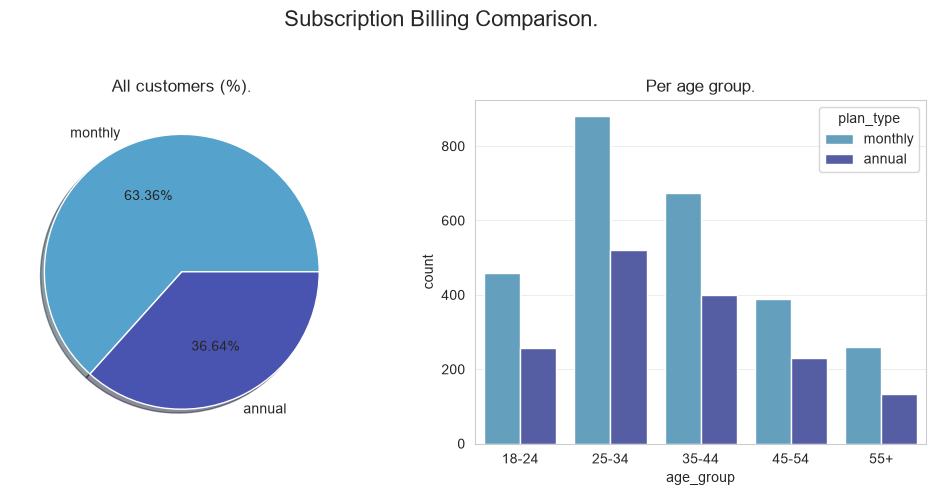

In [245]:
# Comparison between subscription billing preference.
membership_count = subscriptions['plan_type'].value_counts()

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 5))

ax0.pie(membership_count, labels=membership_count.index, colors=(binary_colors_2[0], binary_colors_2[1]), autopct='%.2f%%', shadow=True)
ax0.set_title('All customers (%).', loc='center', fontsize=12)

ax1 = sns.countplot(filtered_df, x='age_group', hue='plan_type', order=age_ascending, palette=binary_colors_2)
ax1.set_title('Per age group.', loc='center', fontsize=12)

plt.suptitle('Subscription Billing Comparison.', fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.80)

#plt.show()
plt.savefig(f'{save_dir}/subscription_billing_comparison.jpg')

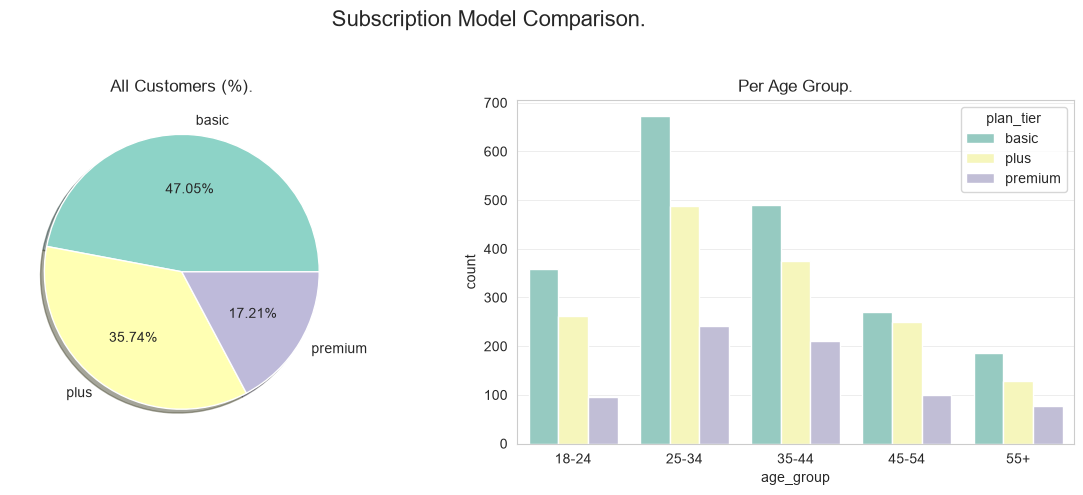

In [270]:
# Subscription model preference comparison.
model_palette = sns.color_palette('Set3')[:3]
subscription_models = subscriptions['plan_tier'].value_counts()

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 5))

ax0.pie(subscription_models, labels=subscription_models.index, colors=model_palette,
        autopct='%.2f%%', shadow=True)
ax0.set_title('All Customers (%).', loc='center', fontsize=12)

ax1 = sns.countplot(filtered_df, x='age_group', hue='plan_tier', order=age_ascending, palette=model_palette)
ax1.set_title('Per Age Group.', loc='center', fontsize=12)

plt.suptitle('Subscription Model Comparison.', fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.80)

#plt.savefig(f'{save_dir}/subscription_model_comparison.jpg')
plt.show()

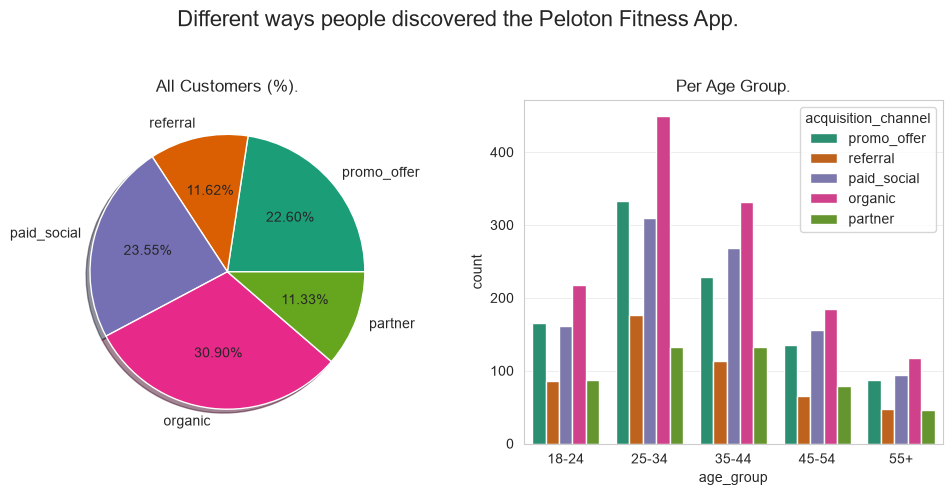

In [268]:
acquisition_all = subscriptions['acquisition_channel'].value_counts(sort=False)

fig, (ax0, ax1)= plt.subplots(1, 2, figsize=(10, 5))

ax0.pie(acquisition_all, labels=acquisition_all.index, colors=sns.color_palette('Dark2'), autopct='%.2f%%', shadow=True)
ax0.set_title('All Customers (%).', loc='center', fontsize=12)

ax1 = sns.countplot(filtered_df, x='age_group', hue='acquisition_channel',
                    order=age_ascending, palette='Dark2')
ax1.set_title('Per Age Group.', loc='center', fontsize=12)

fig.suptitle('Different ways people discovered the Peloton Fitness App.', fontsize=16)
fig.tight_layout()
fig.subplots_adjust(top=0.80)   #Adjusts subtitles

fig.savefig(f'{save_dir}/acquisition_comparison.jpg')

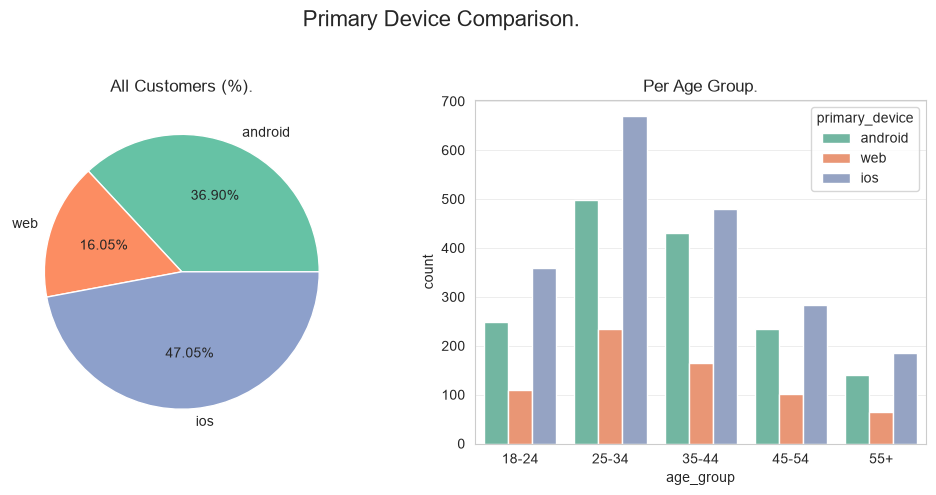

In [271]:
# Primary Device among customers comparison.
device_color = sns.color_palette('Set2')[:3]
device_all = filtered_df['primary_device'].value_counts(sort=False)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 5))
ax0.pie(device_all, labels=device_all.index, autopct='%.2f%%',
        colors=device_color)
ax0.set_title('All Customers (%).', loc='center', fontsize=12)

ax1 = sns.countplot(filtered_df, x='age_group', hue='primary_device', order=age_ascending,
                    palette=device_color)
ax1.set_title('Per Age Group.', fontsize=12)

plt.suptitle('Primary Device Comparison.', fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.80)

#plt.savefig(f'{save_dir}/primary_device_comparison.jpg')
plt.show()